# 08 · Relative speed and flat predictions

**Why:** the deployed Ridge model predicts about five reps left even at the end of video 3. A low average error concealed this behaviour.

**Test:** compare absolute motion with changes relative to earlier reps, and expand the regularization search. Keep the original model unchanged. These are exploratory tests on previously inspected participants, not independent confirmation.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'training/results').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from app.backend.services.motion_features import candidate_features
from app.backend.services.linear_predictor import LinearPredictor

REFERENCE = ROOT / 'training/results/persistent_tremor_20261101T105947439502Z'
OUTPUT = ROOT / 'training/results/relative_speed_followup'
OUTPUT.mkdir(exist_ok=True)
SPEED = ['speed_mean', 'speed_p90', 'speed_current', 'speed_change']
SHAKING = ['transverse_log_rms', 'transverse_power_fraction', 'transverse_peak_fraction']
RECENT = ['current_speed_ratio', 'recent_speed_slope', 'current_up_time_ratio', 'recent_up_time_slope']
EARLY = ['early_speed_ratio', 'early_up_time_ratio']
ALPHAS = [.001, .01, .1, 1., 10., 100., 1000.]
base = pd.read_csv(REFERENCE / 'deployment_features.csv')
assert not base.duplicated(['video_id', 'rep']).any()
print(f'{len(base)} original examples; {base.participant_id.nunique()} people.')

33 original examples; 4 people.


## 1 · Build features from completed reps

Use the last four completed reps. Compare the current lift with those earlier lifts. A separate comparison uses the first three reps as a personal reference. No final rep count, future frame, participant identity, or RIR label is an input.

The first-three-rep reference must pass tracking checks. Report missing references rather than filling them with invented values. Cached pixel traces are only needed when rebuilding the packaged feature table.

In [2]:
def lift_speeds(flow, history):
    start, end = float(history.start_s.min()), float(history.end_s.max())
    check, reason = candidate_features(flow, start, end, float(history.start_s.iloc[-1]))
    if check is None:
        return None, reason
    part = flow.loc[flow.time_s.between(start, end)].copy()
    side = check['side']
    displacement = part[[f'{side}_dx', f'{side}_dy']].interpolate(limit=2).to_numpy(float)
    velocity = displacement / (part.dt.to_numpy()[:, None] * float(part.shoulder_px.median()))
    fs = 1 / float(part.dt.median())
    smooth = sosfiltfilt(butter(3, 3, fs=fs, output='sos'), velocity, axis=0)
    magnitude = np.linalg.norm(smooth, axis=1)
    times = part.time_s.to_numpy()
    speeds = []
    for rep in history.itertuples():
        selected = magnitude[(times >= rep.start_s) & (times <= rep.top_s)]
        if len(selected) < 3 or rep.top_s <= rep.start_s:
            return None, 'insufficient lifting frames'
        speeds.append(float(selected.mean()))
    return np.asarray(speeds), None

feature_file = OUTPUT / 'features.csv'
quality_file = OUTPUT / 'quality.csv'
if feature_file.exists():
    table = pd.read_csv(feature_file)
    quality = pd.read_csv(quality_file)
else:
    marks = pd.read_csv(ROOT / 'training/data/processed/reviewed_reps.csv')
    records, checks = [], []
    for video, group in base.groupby('video_id', sort=False):
        annotations = marks.loc[marks.video_id.eq(video)].sort_values('rep')
        if annotations.empty or annotations.rep.duplicated().any():
            raise ValueError(f'{video}: missing or ambiguous rep annotations')
        flow_path = ROOT / 'training/data/review/pixel_motion' / f'{video}.csv'
        flow = pd.read_csv(flow_path)
        contract = json.loads(flow_path.with_suffix('.json').read_text())
        assert set(annotations.video_sha256) == {contract['source_sha256']}
        early = annotations.loc[annotations.rep.between(1, 3)]
        early_speeds, early_reason = lift_speeds(flow, early) if len(early) == 3 else (None, 'first three reps missing')
        for row in group.to_dict('records'):
            history = annotations.loc[annotations.rep.between(row['rep'] - 3, row['rep'])]
            if len(history) != 4:
                raise ValueError(f'{video}: four-rep history missing')
            current = history.iloc[-1]
            assert current.reps_left == row['reps_left']
            speeds, reason = lift_speeds(flow, history)
            checks.append({'sample_id': row['sample_id'], 'video_id': video, 'rep': row['rep'],
                           'recent_reason': reason or '', 'early_reason': early_reason or ''})
            if speeds is None:
                continue
            duration = (history.top_s - history.start_s).to_numpy(float)
            speed_ref = float(np.median(speeds[:3]))
            duration_ref = float(np.median(duration[:3]))
            if min(speed_ref, duration_ref) <= 1e-6:
                continue
            record = {**row,
                'current_speed_ratio': speeds[-1] / speed_ref,
                'recent_speed_slope': np.polyfit(np.arange(4), speeds / speed_ref, 1)[0],
                'current_up_time_ratio': duration[-1] / duration_ref,
                'recent_up_time_slope': np.polyfit(np.arange(4), duration / duration_ref, 1)[0],
                'early_speed_ratio': np.nan, 'early_up_time_ratio': np.nan}
            if early_speeds is not None and np.median(early_speeds) > 1e-6:
                record['early_speed_ratio'] = speeds[-1] / np.median(early_speeds)
                record['early_up_time_ratio'] = duration[-1] / float((early.top_s - early.start_s).median())
            records.append(record)
    table, quality = pd.DataFrame(records), pd.DataFrame(checks)
    table.to_csv(feature_file, index=False)
    quality.to_csv(quality_file, index=False)
assert table.sample_id.isin(base.sample_id).all()
assert not table.duplicated('sample_id').any()
display(table.groupby(['participant_id', 'video_id']).agg(examples=('rep', 'size'), early_reference=('early_speed_ratio', 'count')))
print('Each matched comparison below uses exactly the same rows for every model.')
early_people = int(table.loc[table.early_speed_ratio.notna()].participant_id.nunique())
print(f'First-three-rep reference: {early_people} people; nested evaluation requires at least three.')
pd.testing.assert_frame_equal(table[['sample_id', 'reps_left']].sort_values('sample_id').reset_index(drop=True),
    base.loc[base.sample_id.isin(table.sample_id), ['sample_id', 'reps_left']].sort_values('sample_id').reset_index(drop=True), check_dtype=False)

examples  early_reference
participant_id video_id                                
P001           V001                  6                6
               Vfb5fee7743ec         6                0
P002           Vde309ba0dab8         1                0
P003           V5dd65202f184        13                0
P005           V008                  7                7

Each matched comparison below uses exactly the same rows for every model.
First-three-rep reference: 2 people; nested evaluation requires at least three.


## 2 · Evaluate without mixing people

Hold out one person at a time. Choose regularization using only the remaining people's inner validation folds. Scale features using training rows only. Weight participants equally during fitting and scoring.

Compare the original search with a wider search, then test recent ratios and first-three-rep references. The training median is a baseline. Training-set scores are shown separately and never treated as test results.

**Limited follow-up:** low-regularization Ridge still gives a large final-rep error on video 3. Test an RBF support-vector regressor to check a nonlinear relationship, using four predeclared C values, fixed gamma and epsilon, and the same nested participant splits. This adds an exploratory comparison; it does not create a fresh test set.

In [3]:
def fit(train, columns, alpha):
    weights = 1 / train.groupby('participant_id').participant_id.transform('size').to_numpy(float)
    weights *= len(weights) / weights.sum()
    nonlinear = isinstance(alpha, tuple)
    estimator = SVR(C=alpha[1], gamma='scale', epsilon=.5) if nonlinear else Ridge(alpha=alpha)
    model = make_pipeline(StandardScaler(), estimator)
    step = 'svr' if nonlinear else 'ridge'
    model.fit(train[columns], train.reps_left, **{step + '__sample_weight': weights})
    return model

def person_mae(test, prediction):
    return float(pd.DataFrame({'person': test.participant_id.to_numpy(),
                              'error': np.abs(test.reps_left.to_numpy() - prediction)}).groupby('person').error.mean().mean())

def evaluate(cohort, data, specifications):
    people = sorted(data.participant_id.unique())
    if len(people) < 3:
        raise ValueError('At least three people are needed for nested participant validation')
    predictions, selections, curves = [], [], []
    keys = ['sample_id', 'participant_id', 'video_id', 'rep', 'reps_left']
    for person in people:
        train = data.loc[data.participant_id.ne(person)].copy()
        test = data.loc[data.participant_id.eq(person)].copy()
        assert set(train.participant_id).isdisjoint(test.participant_id)
        for name, (columns, alphas) in specifications.items():
            if name == 'training_median':
                values = np.repeat(float(train.reps_left.median()), len(test))
            else:
                candidates = []
                for alpha in alphas:
                    scores = []
                    for validation_person in sorted(train.participant_id.unique()):
                        a = train.loc[train.participant_id.ne(validation_person)]
                        b = train.loc[train.participant_id.eq(validation_person)]
                        values = fit(a, columns, alpha).predict(b[columns])
                        scores.append(person_mae(b, values))
                    score = float(np.mean(scores))
                    candidates.append((score, alpha))
                    curves.append({'cohort': cohort, 'test_person': person, 'model': name, 'alpha': alpha, 'inner_mae': score})
                score, alpha = min(candidates)
                model = fit(train, columns, alpha)
                values = model.predict(test[columns])
                selections.append({'cohort': cohort, 'test_person': person, 'model': name, 'alpha': alpha, 'inner_mae': score})
            record = test[keys].copy()
            record['prediction'] = values
            record['model'], record['cohort'] = name, cohort
            predictions.append(record)
    return pd.concat(predictions, ignore_index=True), pd.DataFrame(selections), pd.DataFrame(curves)

specs = {
    'training_median': ([], []),
    'speed_original_search': (SPEED, [.1, 1., 10., 100.]),
    'shaking_original_search': (SPEED + SHAKING, [.1, 1., 10., 100.]),
    'speed_wider_search': (SPEED, ALPHAS),
    'shaking_wider_search': (SPEED + SHAKING, ALPHAS),
    'relative_speed': (SPEED + RECENT, ALPHAS),
    'relative_speed_shaking': (SPEED + RECENT + SHAKING, ALPHAS),
    'nonlinear_speed': (SPEED, [('svr', value) for value in [.1, 1., 10., 100.]]),
    'nonlinear_speed_shaking': (SPEED + SHAKING, [('svr', value) for value in [.1, 1., 10., 100.]]),
    'nonlinear_relative_speed': (SPEED + RECENT, [('svr', value) for value in [.1, 1., 10., 100.]]),
}
recent = table.dropna(subset=SPEED + SHAKING + RECENT).copy()
predictions, selections, curves = evaluate('recent_history', recent, specs)
early = recent.dropna(subset=EARLY).copy()
if early.participant_id.nunique() >= 3:
    early_specs = {**specs,
        'early_relative_speed': (SPEED + RECENT + EARLY, ALPHAS),
        'early_relative_speed_shaking': (SPEED + RECENT + EARLY + SHAKING, ALPHAS)}
    p, s, q = evaluate('early_reference', early, early_specs)
    predictions = pd.concat([predictions, p], ignore_index=True)
    selections = pd.concat([selections, s], ignore_index=True)
    curves = pd.concat([curves, q], ignore_index=True)
for _, cohort in predictions.groupby('cohort'):
    reference = None
    for _, group in cohort.groupby('model'):
        ids = set(group.sample_id)
        assert not group.sample_id.duplicated().any()
        reference = ids if reference is None else reference
        assert ids == reference
predictions.to_csv(OUTPUT / 'predictions.csv', index=False)
selections.to_csv(OUTPUT / 'inner_selection.csv', index=False)
curves.to_csv(OUTPUT / 'regularization_curves.csv', index=False)
original = pd.read_csv(REFERENCE / 'predictions.csv')
for old, new in [('speed_only', 'speed_original_search'), ('speed_plus_persistent_transverse', 'shaking_original_search')]:
    expected = original.loc[original.model.eq(old), ['sample_id', 'prediction']].set_index('sample_id')
    actual = predictions.loc[predictions.cohort.eq('recent_history') & predictions.model.eq(new), ['sample_id', 'prediction']].set_index('sample_id')
    if set(expected.index) == set(actual.index):
        np.testing.assert_allclose(actual.sort_index().prediction, expected.sort_index().prediction, atol=1e-10)
print('Original held-out predictions reproduced on the matched cohort.')


Original held-out predictions reproduced on the matched cohort.


## 3 · Measure useful behaviour

**Primary:** participant-mean MAE. Also show RMSE, predictions within one/two reps, signed bias, R², MAE at RIR ≤ 2, and error on the final completed rep. R² is undefined for a person with one example.

Per-set curves and prediction spread expose flat estimates. An additional sensitivity table excludes people with only one evaluated example; it is a diagnostic, not a new model-selection dataset.

In [4]:
def metrics(data):
    rows = []
    for (cohort, model, person), group in data.groupby(['cohort', 'model', 'participant_id']):
        error = group.prediction.to_numpy() - group.reps_left.to_numpy()
        absolute = np.abs(error)
        near = group.reps_left.to_numpy() <= 2
        final = group.reps_left.to_numpy() == 0
        rows.append({'cohort': cohort, 'model': model, 'participant_id': person, 'examples': len(group),
            'mae': absolute.mean(), 'rmse': np.sqrt(np.mean(error ** 2)),
            'within_1': np.mean(absolute <= 1), 'within_2': np.mean(absolute <= 2),
            'bias': error.mean(), 'r2': r2_score(group.reps_left, group.prediction) if group.reps_left.nunique() > 1 else np.nan,
            'near_failure_mae': absolute[near].mean() if near.any() else np.nan,
            'final_rep_mae': absolute[final].mean() if final.any() else np.nan})
    people = pd.DataFrame(rows)
    columns = ['mae', 'rmse', 'within_1', 'within_2', 'bias', 'r2', 'near_failure_mae', 'final_rep_mae']
    summary = people.groupby(['cohort', 'model'])[columns].mean().reset_index()
    counts = people.groupby(['cohort', 'model']).agg(examples=('examples', 'sum'), people=('participant_id', 'nunique'))
    summary = summary.merge(counts, on=['cohort', 'model'])
    return people, summary

people, summary = metrics(predictions)
people.to_csv(OUTPUT / 'participant_scores.csv', index=False)
summary.to_csv(OUTPUT / 'comparison.csv', index=False)
sensitivity = people.loc[people.examples.ge(2)].groupby(['cohort', 'model']).agg(mae=('mae', 'mean'), people=('participant_id', 'nunique'))
sensitivity.to_csv(OUTPUT / 'sensitivity.csv')
display(summary.round(3))
print('Sensitivity: exclude single-example people')
display(sensitivity.round(3))
trajectory = predictions.groupby(['cohort', 'model', 'participant_id', 'video_id']).agg(
    examples=('rep', 'size'), predicted_min=('prediction', 'min'), predicted_max=('prediction', 'max'),
    actual_min=('reps_left', 'min'), actual_max=('reps_left', 'max'))
trajectory['predicted_span'] = trajectory.predicted_max - trajectory.predicted_min
trajectory.to_csv(OUTPUT / 'trajectory_scores.csv')

,cohort,model,mae,rmse,within_1,within_2,bias,r2,near_failure_mae,final_rep_mae,examples,people
0,recent_history,nonlinear_relative_speed,2.356,2.822,0.402,0.553,-0.285,-0.617,3.021,4.648,33,4
1,recent_history,nonlinear_speed,2.404,2.842,0.402,0.534,-0.275,-0.585,3.081,4.599,33,4
2,recent_history,nonlinear_speed_shaking,2.358,2.782,0.402,0.553,-0.153,-0.492,3.127,4.591,33,4
3,recent_history,relative_speed,2.426,2.881,0.402,0.553,0.035,-0.549,3.438,4.933,33,4
4,recent_history,relative_speed_shaking,2.411,2.883,0.402,0.553,0.078,-0.570,3.507,5.070,33,4
5,recent_history,shaking_original_search,2.221,2.645,0.402,0.553,-0.261,-0.417,3.183,4.589,33,4
6,recent_history,shaking_wider_search,2.390,2.842,0.402,0.553,0.055,-0.511,3.399,4.953,33,4
7,recent_history,speed_original_search,2.251,2.651,0.402,0.553,-0.385,-0.297,2.801,3.982,33,4
8,recent_history,speed_wider_search,2.401,2.838,0.402,0.553,0.003,-0.489,3.319,4.799,33,4
9,recent_history,training_median,2.453,2.923,0.458,0.574,0.042,-0.675,3.400,5.000,33,4


Sensitivity: exclude single-example people


mae  people
cohort         model                                  
recent_history nonlinear_relative_speed  3.081       3
               nonlinear_speed           3.101       3
               nonlinear_speed_shaking   2.989       3
               relative_speed            3.068       3
               relative_speed_shaking    3.067       3
               shaking_original_search   2.962       3
               shaking_wider_search      3.018       3
               speed_original_search     2.871       3
               speed_wider_search        3.014       3
               training_median           3.104       3

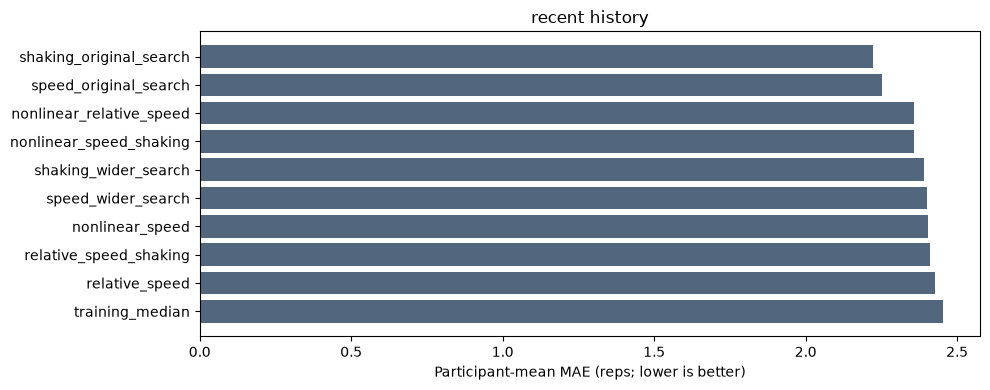

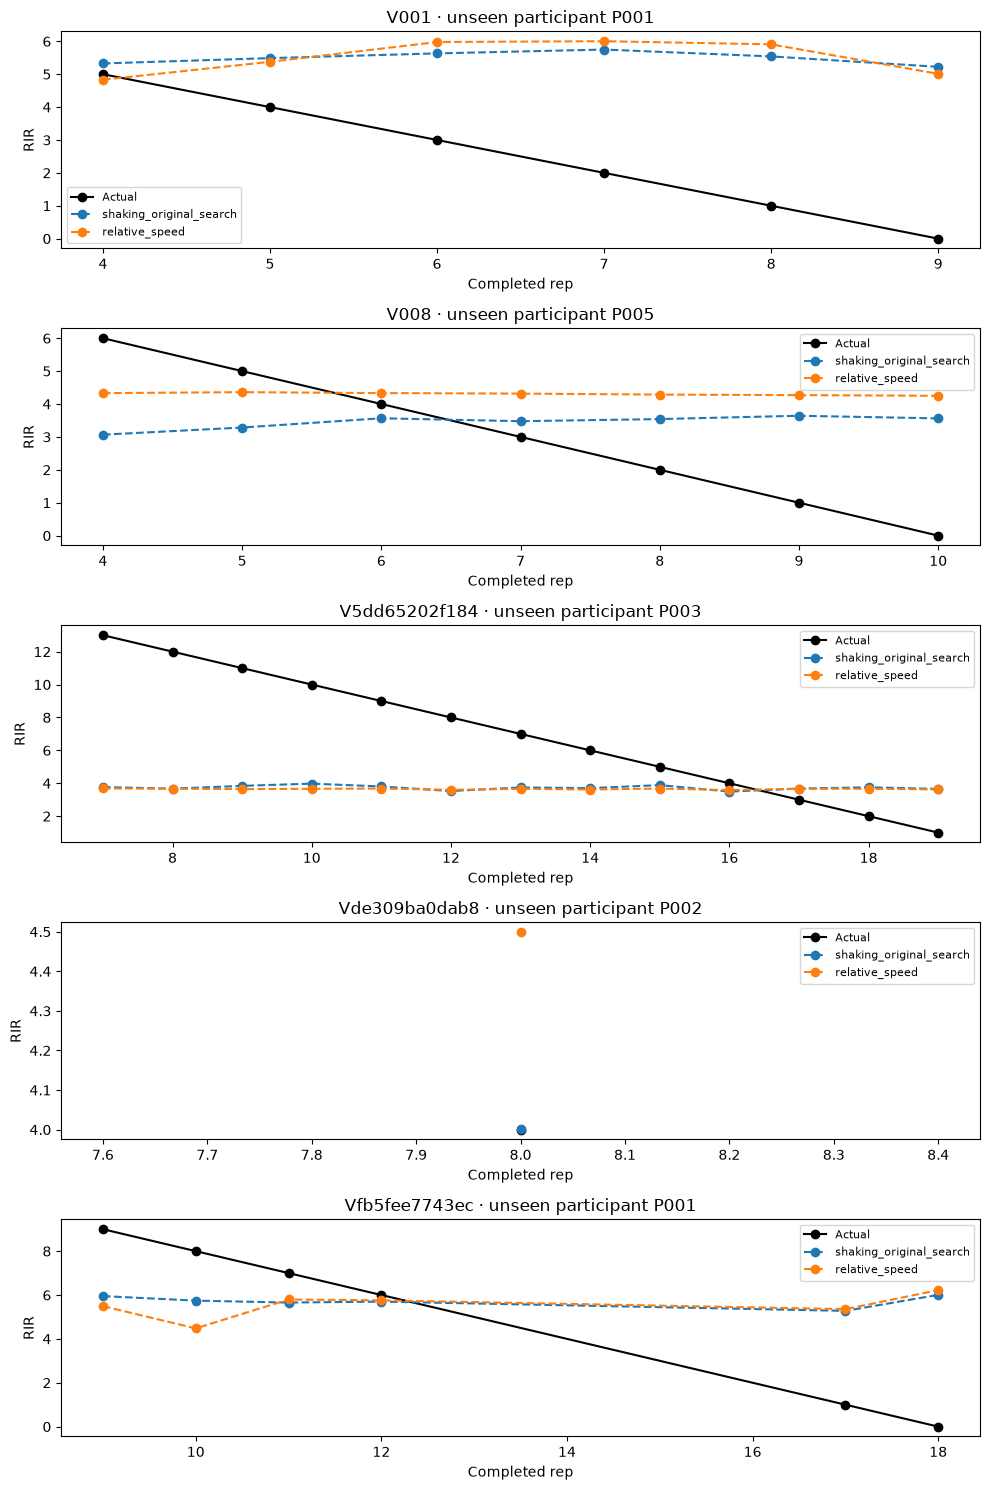

In [5]:
for cohort, group in summary.groupby('cohort'):
    group = group.sort_values('mae')
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(group.model, group.mae, color='#52677d')
    ax.invert_yaxis()
    ax.set(xlabel='Participant-mean MAE (reps; lower is better)', title=cohort.replace('_', ' '))
    fig.tight_layout()
    fig.savefig(OUTPUT / f'{cohort}_comparison.png', dpi=160)
    plt.show()

for cohort, group in predictions.groupby('cohort'):
    eligible = summary.loc[summary.cohort.eq(cohort) & summary.model.ne('training_median')]
    best = eligible.sort_values('mae').model.iloc[0]
    videos = sorted(group.video_id.unique())
    fig, axes = plt.subplots(len(videos), 1, figsize=(10, 3 * len(videos)), squeeze=False)
    for ax, video in zip(axes[:, 0], videos):
        selected = group.loc[group.video_id.eq(video)]
        truth = selected.drop_duplicates('sample_id').sort_values('rep')
        ax.plot(truth.rep, truth.reps_left, 'ko-', label='Actual')
        for name in dict.fromkeys(['shaking_original_search', 'relative_speed', best]):
            line = selected.loc[selected.model.eq(name)].sort_values('rep')
            ax.plot(line.rep, line.prediction, 'o--', label=name)
        ax.set(title=f'{video} · unseen participant {truth.participant_id.iloc[0]}', xlabel='Completed rep', ylabel='RIR')
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUTPUT / f'{cohort}_set_predictions.png', dpi=140)
    plt.show()

## 4 · Separate fitting from generalization

Check whether lower regularization can fit the original training rows at all. These are **training errors**, not evidence of performance on new people. Report video 3 explicitly. Do not choose a deployed model from these training errors.

In [6]:
diagnostics = []
for name, columns in [('speed', SPEED), ('speed_shaking', SPEED + SHAKING)]:
    for alpha in ALPHAS:
        model = fit(base, columns, alpha)
        values = model.predict(base[columns])
        video3 = base.video_id.eq('Vfb5fee7743ec').to_numpy()
        final = video3 & base.reps_left.eq(0).to_numpy()
        diagnostics.append(
            {
                'features': name,
                'alpha': alpha,
                'training_mae': mean_absolute_error(base.reps_left, values),
                'video3_training_mae': mean_absolute_error(
                    base.loc[video3, 'reps_left'], values[video3]
                ),
                'video3_final_prediction': float(values[final][0]),
            }
        )
diagnostics = pd.DataFrame(diagnostics)
diagnostics.to_csv(OUTPUT / 'training_diagnostics.csv', index=False)
display(diagnostics.round(3))

bundle = LinearPredictor(ROOT / 'app/backend/assets/rir_model.json')
deployed = base.loc[base.video_id.eq('Vfb5fee7743ec')].copy()
deployed['deployed_prediction'] = [
    bundle.estimate(row) for row in deployed.to_dict('records')
]
display(deployed[['rep', 'reps_left', 'deployed_prediction']].round(3))

,features,alpha,training_mae,video3_training_mae,video3_final_prediction
0,speed,0.001,2.463,2.486,6.634
1,speed,0.010,2.462,2.480,6.672
2,speed,0.100,2.511,2.731,6.894
3,speed,1.000,2.614,3.042,7.087
4,speed,10.000,2.671,3.104,6.568
5,speed,100.000,2.775,3.203,5.261
6,speed,1000.000,2.891,3.320,4.583
7,speed_shaking,0.001,2.191,2.448,6.157
8,speed_shaking,0.010,2.197,2.438,6.226
9,speed_shaking,0.100,2.269,2.559,6.604


,rep,reps_left,deployed_prediction
6,9,9,5.492
7,10,8,5.331
8,11,7,5.123
9,12,6,5.165
10,17,1,4.681
11,18,0,5.578


In [7]:
config = {
    'reference': REFERENCE.name,
    'reference_sha256': hashlib.sha256((REFERENCE / 'deployment_features.csv').read_bytes()).hexdigest(),
    'feature_sha256': hashlib.sha256(feature_file.read_bytes()).hexdigest(),
    'nonlinear_search': {'model': 'RBF SVR', 'C': [.1, 1., 10., 100.], 'gamma': 'scale', 'epsilon': .5},
    'early_reference_people': early_people,
    'history_reps': 4, 'early_reference_reps': 3, 'regularization': ALPHAS,
    'evaluation': 'nested leave-one-participant-out; participant-weighted fitting and macro MAE; training-only scaling',
    'cohorts': {name: {'examples': int(g.sample_id.nunique()), 'participants': int(g.participant_id.nunique())}
                for name, g in predictions.groupby('cohort')},
    'future_information_inputs': False,
    'limitations': 'Exploratory reused participants; tiny quality-filtered cohort. No independent confirmation or sensor-validated tremor.',
    'deployment_changed': False,
}
(OUTPUT / 'config.json').write_text(json.dumps(config, indent=2) + '\n')
lines = ['# Relative-speed follow-up', '', 'No tested change improved overall held-out MAE over the original model. The deployed model remains unchanged.', '', 'Nested participant-held-out results; exploratory reused data.', '']
for cohort, group in summary.groupby('cohort'):
    baseline = group.loc[group.model.eq('shaking_original_search')].iloc[0]
    best = group.loc[group.model.ne('training_median')].sort_values('mae').iloc[0]
    change = 100 * (baseline.mae - best.mae) / baseline.mae
    lines += [f'## {cohort}', '',
        f'{int(best.examples)} examples, {int(best.people)} people. Best observed: {best.model}, MAE {best.mae:.3f}.',
        f'Original shaking model on the same rows: {baseline.mae:.3f}. Relative difference: {change:.2f}%.',
        f'Best observed near-failure MAE: {best.near_failure_mae:.3f}; final-rep MAE: {best.final_rep_mae:.3f}.', '',
        'Model ranking was inspected after evaluation; this is not an untouched test or proof of deployment quality.', '']
lines += [f'First-three-rep tracking reference passed for only {early_people} people. It was not evaluated with nested participant validation unless at least three people passed.', '', 'The deployed model was not changed. Inspect per-set curves and participant sensitivity before considering promotion.', '']
(OUTPUT / 'README.md').write_text('\n'.join(lines))
print('Saved:', OUTPUT)
print('No deployment or app-model changes made.')
print('Input-history invariance check: changes after a completed window cannot affect its speeds.')
if (ROOT / 'training/data/processed/reviewed_reps.csv').exists():
    marks = pd.read_csv(ROOT / 'training/data/processed/reviewed_reps.csv')
    history = marks.loc[marks.video_id.eq('V001') & marks.rep.between(1, 4)].sort_values('rep')
    flow = pd.read_csv(ROOT / 'training/data/review/pixel_motion/V001.csv')
    before, reason = lift_speeds(flow, history)
    altered = flow.copy()
    future = altered.time_s.gt(float(history.end_s.max()))
    altered.loc[future, ['left_dx', 'left_dy', 'right_dx', 'right_dy']] = 99999.
    after, reason = lift_speeds(altered, history)
    assert before is not None
    np.testing.assert_array_equal(before, after)
    print('Passed.')


Saved: /Users/zkaynl7/Projects/alu/velocity-tremor-ml/training/results/relative_speed_followup
No deployment or app-model changes made.
Input-history invariance check: changes after a completed window cannot affect its speeds.
Passed.


## Decision

None of the tested changes improved overall held-out MAE. Recent relative speed reached about **2.43 reps**, versus **2.22** for the existing model; nonlinear relative speed reached about **2.36**. Predictions remain poor near failure. Lower regularization also failed to solve video 3 using its saved training inputs.

Only two people passed the first-three-rep pixel-tracking reference, so that variant could not support nested participant evaluation. Keep this limitation visible rather than relaxing quality checks after seeing results.

**No app-model promotion.** These features and this small cohort do not demonstrate reliable exact RIR prediction. The per-set plots are necessary alongside the average error.